Nama kolom asli: ['ID', 'NILAI']
Sample data:
   ID  NILAI
0   1     75
1   2     75
2   3     83
3   4     83
4   5     12

Setelah normalisasi:
Nama kolom: ['ID', 'Nilai']


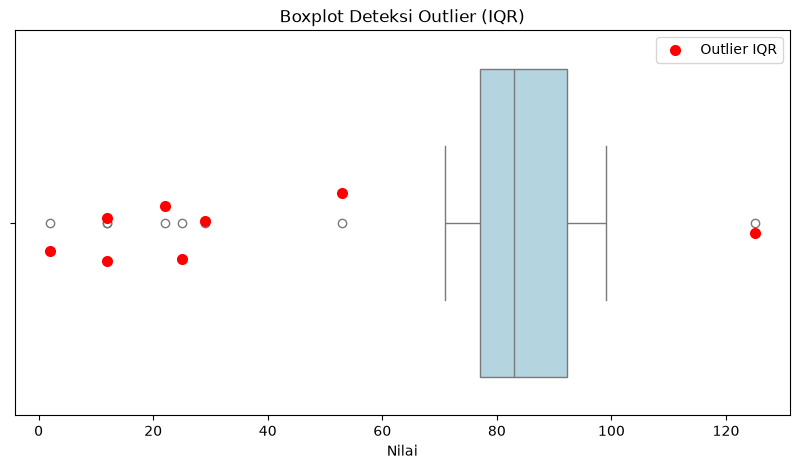

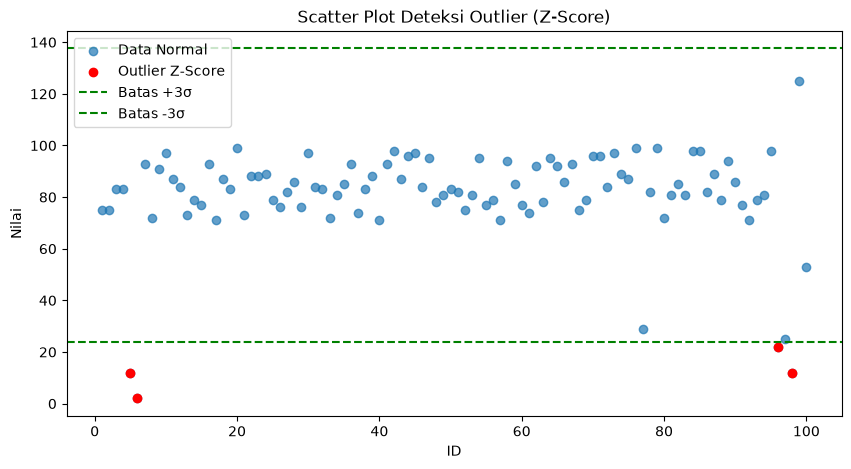

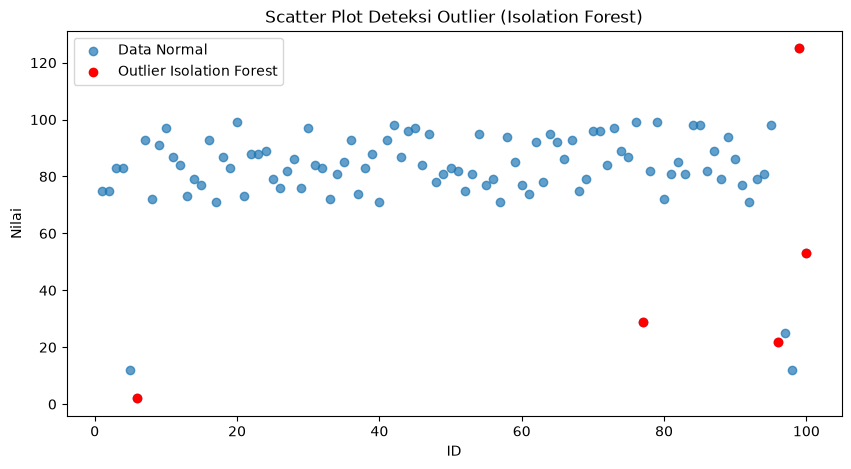

In [ ]:
import numpy as np
from sklearn.ensemble import IsolationForest
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

# Baca CSV
df = pd.read_csv("data.csv")

print("Nama kolom asli:", df.columns.tolist())
print("Sample data:")
print(df.head())

df.columns = df.columns.str.strip().str.upper()

# Rename ke nama yang kita inginkan
if 'ID' in df.columns and 'NILAI' in df.columns:
    df = df.rename(columns={'ID': 'ID', 'NILAI': 'Nilai'})
elif 'ID' in df.columns and 'NILAI' in df.columns:
    pass  # sudah benar
else:
    # Fallback: gunakan kolom pertama dan kedua
    df = df.rename(columns={df.columns[0]: 'ID', df.columns[1]: 'Nilai'})

print("\nSetelah normalisasi:")
print("Nama kolom:", df.columns.tolist())

# Deteksi Outlier
mean = df["Nilai"].mean()
std = df["Nilai"].std()
df["Z-Score"] = (df["Nilai"] - mean) / std
df["Outlier_Z"] = df["Z-Score"].apply(lambda x: abs(x) > 3)

# IQR
Q1 = df["Nilai"].quantile(0.25)
Q3 = df["Nilai"].quantile(0.75)
IQR = Q3 - Q1
lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR
df["Outlier_IQR"] = (df["Nilai"] < lower_bound) | (df["Nilai"] > upper_bound)

# Isolation Forest
iso = IsolationForest(contamination=0.05, random_state=42)
df["Outlier_IForest"] = iso.fit_predict(df[["Nilai"]])
df["Outlier_IForest"] = df["Outlier_IForest"].apply(lambda x: True if x == -1 else False)

# Visualisasi
plt.figure(figsize=(10, 5))
sns.boxplot(x=df["Nilai"], color="lightblue")
outliers_iqr = df[df["Outlier_IQR"] == True]["Nilai"]
sns.stripplot(x=outliers_iqr, color="red", size=8, label="Outlier IQR")
plt.title("Boxplot Deteksi Outlier (IQR)")
plt.legend()
plt.show()

plt.figure(figsize=(10, 5))
plt.scatter(df["ID"], df["Nilai"], label="Data Normal", alpha=0.7)
plt.scatter(
    df[df["Outlier_Z"] == True]["ID"],
    df[df["Outlier_Z"] == True]["Nilai"],
    color="red", label="Outlier Z-Score"
)
plt.axhline(df["Nilai"].mean() + 3 * df["Nilai"].std(), color="green", linestyle="--", label="Batas +3σ")
plt.axhline(df["Nilai"].mean() - 3 * df["Nilai"].std(), color="green", linestyle="--", label="Batas -3σ")
plt.title("Scatter Plot Deteksi Outlier (Z-Score)")
plt.xlabel("ID")
plt.ylabel("Nilai")
plt.legend()
plt.show()

plt.figure(figsize=(10, 5))
plt.scatter(df["ID"], df["Nilai"], label="Data Normal", alpha=0.7)
plt.scatter(
    df[df["Outlier_IForest"] == True]["ID"],
    df[df["Outlier_IForest"] == True]["Nilai"],
    color="red", label="Outlier Isolation Forest"
)
plt.title("Scatter Plot Deteksi Outlier (Isolation Forest)")
plt.xlabel("ID")
plt.ylabel("Nilai")
plt.legend()
plt.show()